# Faire calculer la machine

| Module | Durée | Prérequis |
|---|---|---|
| M0 – Python et NumPy comme outils | 75 min | aucun |

In [13]:
# Style graphique Liouaï : couleurs du logo, axes sobres
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

LIOUAI = {"navy": "#243743", "vert": "#28B78D", "vert_texte": "#167A5C", "gris": "#A1A9AE",
          "gris_texte": "#5C6870", "jaune": "#E5C800", "fond": "#F3F5F6"}
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=[LIOUAI["vert"], LIOUAI["navy"], LIOUAI["gris"],
                                         LIOUAI["jaune"], LIOUAI["vert_texte"], LIOUAI["gris_texte"]]),
    "axes.edgecolor": LIOUAI["gris"], "axes.labelcolor": LIOUAI["navy"],
    "axes.titlecolor": LIOUAI["navy"], "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": LIOUAI["gris_texte"], "ytick.color": LIOUAI["gris_texte"],
    "text.color": LIOUAI["navy"], "grid.color": "#E1E6E9", "legend.frameon": False,
    "font.family": "sans-serif", "font.sans-serif": ["Roboto", "Helvetica", "Arial", "DejaVu Sans"],
    "figure.dpi": 100,
})
# Dégradé de marque : gris clair -> vert -> navy (et sa version inversée)
if "liouai" not in mpl.colormaps:
    _cmap = LinearSegmentedColormap.from_list("liouai", [LIOUAI["fond"], LIOUAI["vert"], LIOUAI["navy"]])
    mpl.colormaps.register(_cmap)
    mpl.colormaps.register(_cmap.reversed())

## ① Définir la question

Camille tient le budget de son foyer. Elle a noté, pour chacun des 12 derniers mois, ses dépenses dans quatre catégories : **logement, courses, transport, loisirs**. Elle se demande si elle dépense « trop en courses » et quel mois a été le plus coûteux.

**Activité** : « Trop en courses » n'est pas une question qu'on peut calculer. Proposez une ou deux questions précises, auxquelles un calcul peut répondre.

Indiquez vos réponses et justifiez-les.

Dans la suite, on retient deux questions :

1. **Quelle part (en %) du budget annuel va aux courses ?**
2. **Quel mois a été le plus coûteux, et à cause de quelle catégorie ?**

## ② Estimer avant de calculer

En France, l'alimentation représente souvent entre 15 % et 20 % du budget d'un ménage. Avant de regarder les données de Camille, pariez.

In [14]:
pari_part_courses = 20    # en %, modifiez

## ③ Abstraire : choisir une technologie

Les données forment un **tableau** de 12 lignes (les mois) et 4 colonnes (les catégories). Pour le traiter, plusieurs technologies sont possibles :

| Technologie | Avantage | Limite |
|---|---|---|
| Calcul mental ou papier | aucune installation | 48 nombres : long et source d'erreurs |
| Calculatrice | rapide pour une somme | pas de mémoire du tableau, refaire tout à chaque question |
| Tableur | visuel, familier | formules dispersées, difficiles à réutiliser et à vérifier |
| Python « pur » (listes et boucles) | tout est écrit et rejouable | il faut écrire chaque boucle |
| Python avec NumPy (tableaux) | une opération agit sur tout le tableau | une notation à apprendre |

**Activité** : Pour la question 1, quelle technologie choisiriez-vous si vous n'aviez que ces 12 mois ? Et si vous aviez 10 ans de relevés pour 500 foyers ?

Indiquez vos réponses et justifiez-les.

## ④ Calculer

### Les données

En Python, un tableau peut s'écrire comme une **liste de listes** : une liste par mois, chacune contenant 4 nombres (en euros).

In [15]:
categories = ["logement", "courses", "transport", "loisirs"]
mois = ["jan", "fév", "mar", "avr", "mai", "juin", "juil", "août", "sep", "oct", "nov", "déc"]

depenses_liste = [
    [850, 410, 120,  90],
    [850, 385, 115,  60],
    [850, 420, 130,  85],
    [850, 395, 125, 110],
    [850, 430, 140, 150],
    [850, 445, 135, 180],
    [850, 470, 210, 420],
    [850, 455, 230, 510],
    [850, 415, 130, 140],
    [850, 400, 125,  95],
    [850, 410, 120,  80],
    [850, 520, 145, 260],
]

### Version 1 : Python « pur »

On parcourt les mois avec une boucle `for` et on additionne la deuxième case (indice 1, car Python compte à partir de 0).

In [16]:
total_courses = 0
for ligne in depenses_liste:
    total_courses = total_courses + ligne[1]

total_general = 0
for ligne in depenses_liste:
    for montant in ligne:
        total_general = total_general + montant

print("Courses sur l'année :", total_courses, "€")
print("Budget total        :", total_general, "€")
print("Part des courses    :", round(100 * total_courses / total_general, 1), "%")

Courses sur l'année : 5155 €
Budget total        : 19260 €
Part des courses    : 26.8 %


Cela fonctionne, mais chaque nouvelle question demande une nouvelle boucle. Essayez de trouver le mois le plus coûteux de cette façon : c'est faisable, mais long.

### Version 2 : NumPy

NumPy transforme la liste de listes en **tableau** (`array`). Une seule opération agit alors sur tout le tableau.

In [17]:
import numpy as np

D = np.array(depenses_liste)
print("Forme du tableau :", D.shape)   # (nombre de lignes, nombre de colonnes)

Forme du tableau : (12, 4)


**Lire la notation.** `D.shape` vaut `(12, 4)` : 12 lignes, 4 colonnes. Le paramètre `axis` dit dans quelle direction on « écrase » le tableau :

- `D.sum(axis=0)` additionne **en descendant les lignes** : on obtient un total par colonne, donc **par catégorie** (4 nombres) ;
- `D.sum(axis=1)` additionne **le long de chaque ligne** : on obtient un total par ligne, donc **par mois** (12 nombres).

![Schéma : axis=0 additionne chaque colonne, axis=1 additionne chaque ligne](../../assets/schemas/schema-axis.svg)

In [18]:
par_categorie = D.sum(axis=0)
par_mois = D.sum(axis=1)

print("Total par catégorie :", dict(zip(categories, par_categorie.tolist())))
print("Total par mois      :", dict(zip(mois, par_mois.tolist())))
print("Part des courses    :", round(100 * par_categorie[1] / D.sum(), 1), "%")

Total par catégorie : {'logement': 10200, 'courses': 5155, 'transport': 1725, 'loisirs': 2180}
Total par mois      : {'jan': 1470, 'fév': 1410, 'mar': 1485, 'avr': 1480, 'mai': 1570, 'juin': 1610, 'juil': 1950, 'août': 2045, 'sep': 1535, 'oct': 1470, 'nov': 1460, 'déc': 1775}
Part des courses    : 26.8 %


In [19]:
i = par_mois.argmax()          # indice du plus grand total mensuel
print("Mois le plus coûteux :", mois[i], "-", par_mois[i], "€")
print("Détail de ce mois     :", dict(zip(categories, D[i].tolist())))

Mois le plus coûteux : août - 2045 €
Détail de ce mois     : {'logement': 850, 'courses': 455, 'transport': 230, 'loisirs': 510}


**Activité** : Complétez la cellule suivante pour calculer :

1. la dépense **moyenne** par catégorie (indice : `D.mean(axis=...)`) ;
2. les mois où les loisirs dépassent leur moyenne annuelle (indice : comparez la colonne `D[:, 3]` à un nombre).

In [20]:
moyenne_par_categorie = None      # à compléter
mois_loisirs_eleves = None        # à compléter

print(moyenne_par_categorie)
print(mois_loisirs_eleves)

None
None


## ⑤ Interpréter

Un graphique empilé montre d'un coup d'œil ce qui fait varier le total d'un mois à l'autre.

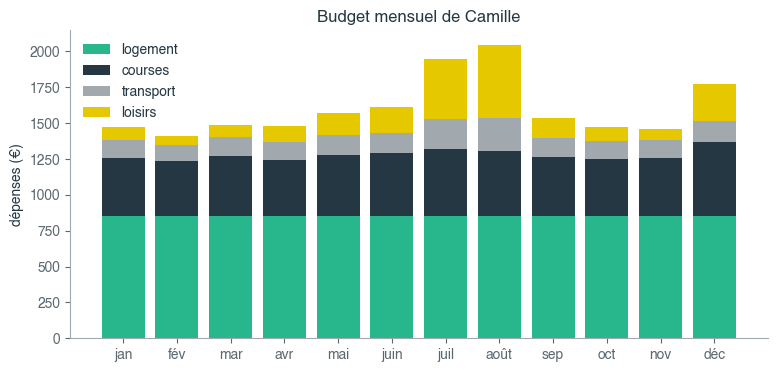

Votre pari : 20 % ; part réelle des courses : 26.8 %


In [21]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))
bas = np.zeros(len(mois))
for j, cat in enumerate(categories):
    ax.bar(mois, D[:, j], bottom=bas, label=cat)
    bas = bas + D[:, j]
ax.set_ylabel("dépenses (€)")
ax.set_title("Budget mensuel de Camille")
ax.legend(loc="upper left")
plt.show()

print(f"Votre pari : {pari_part_courses} % ; part réelle des courses : {100 * par_categorie[1] / D.sum():.1f} %")

**Activité** :

1. Répondez aux deux questions de départ par une phrase chacune, en euros ou en %, dans le langage de Camille.
2. Quelle catégorie explique les pics de l'été ? Et celui de décembre ?
3. Votre pari était-il loin ? D'où venait l'écart ?

Indiquez vos réponses et justifiez-les.

## ⑥ Critiquer et généraliser

- **Hypothèse fragile.** On a supposé que ces 12 mois sont représentatifs. Que changerait une année avec un déménagement ?
- **Vérifier autrement.** Le total général calculé par la version 1 est-il le même que `D.sum()` ? Vérifiez-le.
- **Généraliser.** Si Camille ajoute une cinquième catégorie (« santé »), quelles lignes de code faut-il modifier ? Lesquelles fonctionnent sans changement ?

In [22]:
print("Version 1 :", total_general, " Version 2 :", D.sum(), " Identiques :", total_general == D.sum())

Version 1 : 19260  Version 2 : 19260  Identiques : True


## Corrigé de l'exercice

*À n'ouvrir qu'après avoir cherché.*

In [23]:
moyenne_par_categorie = D.mean(axis=0)
mois_loisirs_eleves = [m for m, v in zip(mois, D[:, 3]) if v > D[:, 3].mean()]
print(dict(zip(categories, moyenne_par_categorie.round(1).tolist())))
print(mois_loisirs_eleves)

{'logement': 850.0, 'courses': 429.6, 'transport': 143.8, 'loisirs': 181.7}
['juil', 'août', 'déc']


## Bilan — auto-évaluation

Pour chaque compétence travaillée dans ce notebook, choisissez un niveau : **0** non observé · **1** guidé · **2** autonome · **3** transfert.
La cellule enregistre votre bilan dans `progression.json`, à la racine du site.

In [24]:
import json, datetime, pathlib

bilan = {
    "Préparer des entrées correctes pour l'outil": 1,
    "Appliquer l'outil": 1,
    "Choisir une technologie appropriée": 1,
    "Lire les représentations et notations courantes": 1,
}   # modifiez les niveaux

ici = pathlib.Path.cwd()
racine = next((p for p in [ici, *ici.parents] if (p / "myst.yml").exists()), ici)
fichier = racine / "progression.json"
historique = json.loads(fichier.read_text(encoding="utf-8")) if fichier.exists() else []
historique.append({"notebook": "0.1-faire-calculer", "date": datetime.date.today().isoformat(), "niveaux": bilan})
fichier.write_text(json.dumps(historique, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Bilan enregistré ({len(historique)} entrée(s) dans {fichier.name}).")

Bilan enregistré (2 entrée(s) dans progression.json).
